# Hälsoanalys

**Data:** Dataset (CSV): health_study_dataset.csv. Kolumner: age (år), sex (M/F), height (cm), weight (kg), systolic_bp (mmHg), cholesterol (mmol/L), smoker (Yes/No), disease (0/1).

#### Slutsats och rekommendation

**Beskrivande analys:** Det systoliska blodtrycket är ungefär normalfördelat. Grupperna rökare och icke-rökare har olika storlek. 73,4% röker och 26,6% röker inte av de 800 som undersökts. 

**Simulering** av andelen personer i datasetet som har sjukdomen: Den simulerade sjukdomsandelen på 5,6% ligger nära den verkliga andelen i studien på 5,9%.

**Konfidensintervall** för blodtryckets medelvärde: De två intervallens nedre och övre gränser är mycket lika och tyder det på att metoderna ger ungefär samma uppskattning av osäkerheten. Båda metoderna ger 95%-igt konfidensintervall på 148-150 mmHg. Stickprovets medelvärde är 149,18 mmHg. Intervallet är ganska smalt och det kan tyda på att skattningen är nära populationens medelvärde. 
 
**Hypotesprövning** ”Rökare har högre medel-blodtryck än icke-rökare”: Det genomsnittliga systoliska blodtrycket var 149,52 mmHg hos rökare och 149,05 mmHg hos icke-rökare. Skillnaden mellan gruppernas medelvärden är liten, ca 0,47mmHg. Resultatet visar inte något statistiskt signifikant stöd för att rökning är förknippat med ett högre systoliskt blodtryck.

**Power:** Simulering görs för att undersöka hur säkert hypotestestet är. Skillnaden mellan gruppernas medelvärden var 0,47mmHg. Vid den simulerade effektstorleken på 0,47 mmHg blev power 10,85%. Det innebär att en effekt av den storleken skulle upptäckas i ungefär 11% av simuleringarna. Med andra ord är det 89 procents risk att testet inte upptäcker skillnaden trots att den faktiskt finns.

**Rekommendation:** Ett större underlag behövs för en mer tillförlitlig analys av skillnaderna.

In [46]:
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Konfiguration
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True            
plt.rcParams["figure.dpi"] = 120
np.set_printoptions(precision=3)
pd.set_option("display.precision", 3)
plt.style.use("seaborn-v0_8-whitegrid")

### Hämtar in och kontrollerar datakvalitet

In [47]:
# Läser in data
df_raw = pd.read_csv("data/health_study_dataset.csv")

display(df_raw.head())
display(df_raw.info())
# Kontrollerar om det finns NaN
display(df_raw.isna().sum())
display(df_raw.describe())

# Kontrollerar om det finns dubletter
duplicated_count = df_raw.duplicated(keep=False).sum()
print("Antal dubletter:", duplicated_count)

# Dubbelkollar genom att printa unika
print("Antal unika värden:", df_raw.nunique())

valid_values = {
    "disease": [0, 1],
    "smoker": ["No", "Yes"],
    "sex": ["F", "M"]
}

invalid_counts = {}

for col, valid in valid_values.items():
    invalid_mask = ~df_raw[col].isin(valid) & df_raw[col].notna()
    invalid_counts[col] = invalid_mask.sum()

display(invalid_counts)

# Låter dropna() stå med för att göra den mer robust
assert set(df_raw["sex"].dropna().unique()) <= {"F", "M"}
assert set(df_raw["smoker"].dropna().unique()) <= {"No", "Yes"}
assert set(df_raw["disease"].dropna().unique()) <= {0, 1}

# För att ska gå att göra tester bör grupperna vara tillräckligt stora
group_sizes = df_raw.groupby("smoker")["systolic_bp"].size()
assert (group_sizes >= 20).all(), "För få observationer i någon grupp!"

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


None

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.000,800.000,800.000,800.000,800.000,800.000,800.000
mean,400.500,49.426,171.849,73.413,149.179,4.929,0.059
std,231.084,14.501,9.804,13.685,12.793,0.848,0.235
min,1.000,18.000,144.400,33.700,106.800,2.500,0.000
25%,200.750,39.000,164.775,64.800,140.900,4.328,0.000
50%,400.500,50.000,171.350,73.200,149.400,4.970,0.000
75%,600.250,59.000,178.925,82.600,157.600,5.482,0.000
max,800.000,90.000,200.400,114.400,185.900,7.880,1.000


Antal dubletter: 0
Antal unika värden: id             800
age             70
sex              2
height         351
weight         424
systolic_bp    385
cholesterol    303
smoker           2
disease          2
dtype: int64


{'disease': np.int64(0), 'smoker': np.int64(0), 'sex': np.int64(0)}

Snabb kontroll
- Kolumnerna saknar NaN värden
- Det finns inga dubetter
- Värdena är verkar rimliga
- I kolumnerna smoker, disease, sex är det två unika värden vardera och det stämmer med vad som förväntas. Id har 800 unika värden och det är ju också rimligt.
- Datatyper: Eftersom disease innehåller 0/1 så passar int64. Kolumnerna smoker och sex har datatypen str och de skulle kunna vara kategoriska variabler.

In [48]:
# Kolumnerna smoker och sex sätts till kategoriska
df = df_raw.copy()
df["sex"]= df["sex"].astype("category")
df["smoker"]= df["smoker"].astype("category")

# Dubbelkollar 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   id           800 non-null    int64   
 1   age          800 non-null    int64   
 2   sex          800 non-null    category
 3   height       800 non-null    float64 
 4   weight       800 non-null    float64 
 5   systolic_bp  800 non-null    float64 
 6   cholesterol  800 non-null    float64 
 7   smoker       800 non-null    category
 8   disease      800 non-null    int64   
dtypes: category(2), float64(4), int64(3)
memory usage: 45.6 KB


## Beskrivande analys

In [49]:
summary = df[[
    "age",
    "weight",
    "height",
    "systolic_bp",
    "cholesterol"
]].agg(
    ["mean", "median", "min", "max"]
)

display(summary)

,age,weight,height,systolic_bp,cholesterol
mean,49.426,73.413,171.849,149.179,4.929
median,50.000,73.200,171.350,149.400,4.970
min,18.000,33.700,144.400,106.800,2.500
max,90.000,114.400,200.400,185.900,7.880


**Tolkning:** Åldern i stickprovet är i spannet 18 och 90 år. Vikten ligger från 33,7 till 114,4 kg och längden i spannet 144,4 till 200,4 cm. Det systoliska blodtrycket ligger i spannet 106,8 och 185,9 mmHg. Som jämförelse räknas 120 mmHg som ett viloblodtryck, 140 mmHg och över räknas som högt blodtryck/hypertoni (wikipedia). Kolesterolvärdena varierar mellan 2,5 och 7,9 mmol/L.

Medelvärdena och medianerna ligger ganska nära varandra för alla variabler. Det kan betyda att det inte finns så många extremvärden som påverkar medelvärdet. För ålder och kolesterol är medelvärdet något lägre än medianen, medan det för vikt och systoliskt blodtryck är något högre.

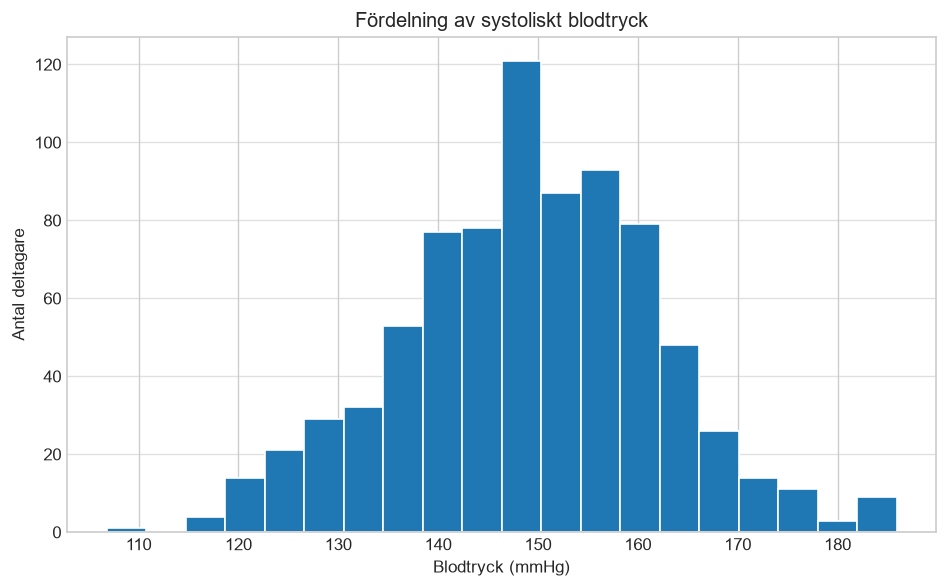

In [50]:
# Histogram för blodtryck
plt.figure()

plt.hist(
    df["systolic_bp"],
    bins=20,
    edgecolor="white"
)

plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Blodtryck (mmHg)")
plt.ylabel("Antal deltagare")
plt.grid(axis="y", alpha=0.6)
plt.tight_layout()
plt.show()

**Tolkning:** Fördelningen liknar en normalfördelning. Den är klockformad och relativt symmetrisk. Men med en marginellt längre svans åt vänster, vilket kan tyda på en mycket svag vänsterskevhet. De flesta av observationerna ligger runt 150 mmHg i blodtryck.

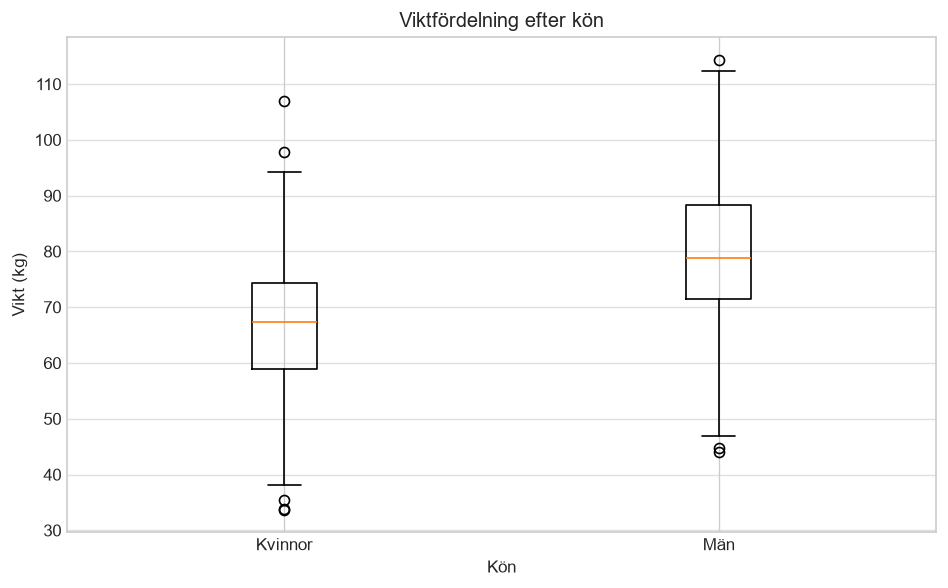

In [51]:
# Boxplot över vikt efter kön
female_weight = df.loc[df["sex"] == "F", "weight"].dropna()
male_weight = df.loc[df["sex"] == "M", "weight"].dropna()

plt.boxplot(
    [female_weight, male_weight],
    tick_labels=["Kvinnor", "Män"]
)

plt.title("Viktfördelning efter kön")
plt.xlabel("Kön")
plt.ylabel("Vikt (kg)")
plt.grid(axis="y", alpha=0.6)
plt.tight_layout()
plt.show()

**Tolkning:** Viktfördelningen skiljer sig mellan män och kvinnor. Män har en högre medianvikt och större IQR, vilket betyder att vikten varierar mer bland män än bland kvinnor. Boxarna överlappar lite, men det finns ändå en tydlig skillnad mellan grupperna. Det finns ett extremvärde för högre vikt bland män och två bland kvinnor. För lägre vikter finns två extremvärden i båda grupperna. Medianen ligger längre ner i boxen för män och mer i mitten för kvinnor. Whiskers har ungefär samma längd ovanför som nedanför boxarna i båda grupperna. Det skulle kunna tyda på att viktfördelningen är ganska är symmetrisk.

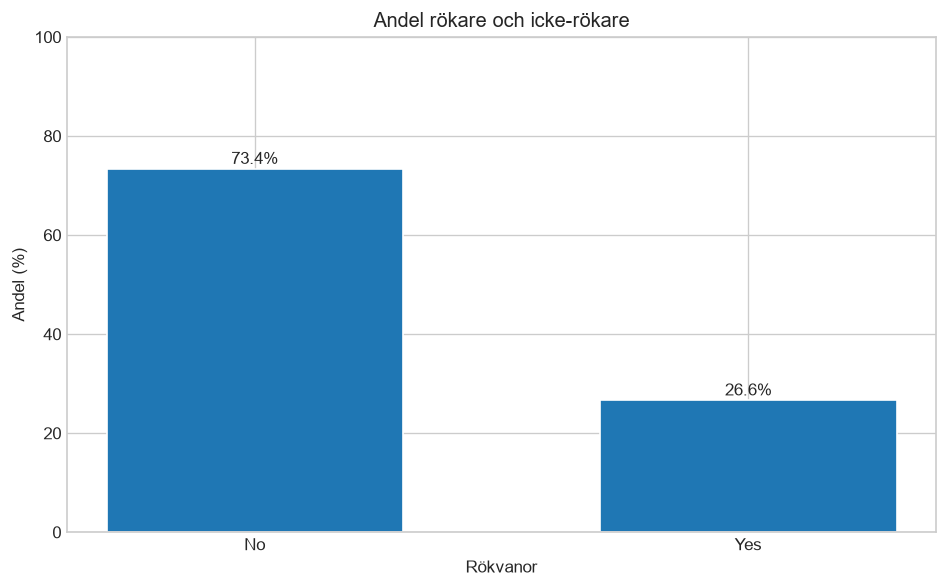

,antal,andel (%)
smoker,,
No,587,73.375
Yes,213,26.625


In [52]:
smoker_summary = pd.DataFrame({
    "antal": df["smoker"].value_counts(),
    "andel (%)": df["smoker"].value_counts(normalize=True) * 100
})

# Stapeldiagram över andelen rökare
plt.bar(
    smoker_summary["andel (%)"].index,
    smoker_summary["andel (%)"].values,
    edgecolor="white",
    width=0.6
)
for i, value in enumerate(smoker_summary["andel (%)"].values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, 100)
plt.title("Andel rökare och icke-rökare")
plt.xlabel("Rökvanor")
plt.ylabel("Andel (%)")
plt.tight_layout()
plt.show()
display(smoker_summary)

**Tolkning:** Stapeldiagrammet visar fördelningen mellan rökare och icke-rökare i studien. 73,4% röker och 26,6% röker inte av de 800 som undersökts. Grupperna rökare och icke-rökare har alltså olika storlek.

## Simulering

Simuleringen undersöker hur mycket andelen personer med en sjukdom kan variera vid ett slumpmässigt urval av 1 000 personer. Binomialfördelningen används eftersom utfallet är binärt: en person är antingen sjuk eller inte (1 eller 0). Genom att sätta ett slumpmässigt seed blir simuleringen repeterbar och kan återskapas.

In [53]:
# Gör simuleringar repeterbara
np.random.seed(42)

# Beräkna den verkliga sjukandelen i studien
real_proportion = df["disease"].mean()

# Simulerar 1 000 personer
simulation = np.random.binomial(
    n=1,
    p=real_proportion,
    size=1000
)

# Beräknar den simulerade sjukandelen
simulated_proportion = simulation.mean()

print("Verklig andel:", round(real_proportion, 3))
print("Simulerad andel:", round(simulated_proportion, 3))
print(f"Verklig andel i procent: {real_proportion * 100:.2f}%")
print(f"Simulerad andel i procent: {simulated_proportion * 100:.2f}%")

Verklig andel: 0.059
Simulerad andel: 0.056
Verklig andel i procent: 5.88%
Simulerad andel i procent: 5.60%


**Tolkning:** Den verkliga sjukdomsförekomst är 5,9% och simulerad 5,6%. Dvs om vi har 1000 personer så är 59 av dem sjuka jämfört med 56 personer i simuleringen. Den simulerade sjukdomsandelen ligger alltså nära den verkliga andelen i studien. Det observerade resultatet varierar mellan olika urval på grund av slumpmässig variation. Resultaten kan skilja sig åt även om sannolikheten för sjukdom är samma för varje person. Ju fler som ingår desto mindre slumpvariation och desto stabilare uppskattning. 

Begränsningar
- Simuleringen antar att varje person har samma sannolikhet att ha sjukdomen och att observationerna är oberoende av varandra. Det är en förenkling eftersom sjukdom i verkligheten kan påverkas av andra saker, såsom ålder, kön och livsstil.
- Simulering bygger på det befintliga datasetets sjukandel. Om det dataset inte är representativt för populationen så kan simuleringen bli missvisande.

## Konfidensintervall för blodtryckets medelvärde

#### Ett 95% konfidensintervall för medelvärdet med normalapproximation
Normalapproximationen är en relativt snabb metod. Den innebär att en normalfördelning kan användas som approximation när stickprovet är tillräckligt stort och observationerna är tillräckligt oberoende. I studien ingår 800 personer. Det är bra förutsättningar till att kunna använda metoden. Metoden gör det möjligt att beräkna ett konfidensintervall för populationens medelvärde utifrån stickprovets medelvärde och standardavvikelse. Konfidensintervallet beräknas med ett kritiskt z-värde på 1,96, vilket motsvarar en konfidensnivå på 95%.

In [54]:
# Hämta blodtryck
bp = df["systolic_bp"]

n = len(bp)
mean_bp = bp.mean()
std_bp = bp.std(ddof=1)

z = 1.96
standard_error = std_bp / np.sqrt(n)

lower_normal = mean_bp - z * standard_error
upper_normal = mean_bp + z * standard_error

print("Normalapproximation:")
print(f"Medelvärde: {mean_bp:.2f}")
print(f"95% konfidensintervall: {lower_normal:.2f} – {upper_normal:.2f}")

Normalapproximation:
Medelvärde: 149.18
95% konfidensintervall: 148.29 – 150.07


**Tolkning:** Medelvärdet är 149,18 mmHg och det 95-procentiga konfidensintervallet ligger mellan 148,29 och 150,07 mmHg. Det innebär att det uppskattade genomsnittliga systoliska blodtrycket i populationen ligger inom intervallet med en konfidensnivå på 95 %. Eftersom det är ganska smalt så tyder det på att uppskattningen är relativt säker.

Begränsningar
- Normalapproximationen bygger på att stickprovet är tillräckligt stort och att observationerna är tillräckligt oberoende. 

- Den kan fungera sämre vid små stickprov eller om vi har för extrema värden. 
Om saknade värden har tagits bort, så kan det också påverka om bortfallet inte är slumpmässigt. Eftersom vi har ett stickprov på 800 personer så är normalapproximationen ganska robust. Men det kan hända att studiens 800 observationer inte är representativa för hela populationen.

- Populationens standardavvikelse finns inte tillgängligt här och resultatet vi får är en uppskattning av populationens genomsnittliga systoliska blodtryck.

#### Ett 95% konfidensintervall för medelvärdet med bootstrap

Bootstrapmetoden används för att uppskatta osäkerheten utan att behöva anta att originaldatan är normalfördelad. Metoden innebär att många nya stickprov skapas genom att slumpmässigt dra observationer från originaldatasetet med återläggning. För varje nytt stickprov beräknas ett medelvärde. Genom att upprepa processen 10 000 gånger kan man undersöka hur mycket medelvärdet varierar och på så sätt uppskatta osäkerhet


In [55]:
# Sätt seed för reproducerbarhet
np.random.seed(42)

# Antal bootstrap-simuleringar
n_boot = 10_000

boot_means = []

# Skapar nya stickprov med återläggning
for i in range(n_boot):
    sample = np.random.choice(
        bp,
        size=len(bp),
        replace=True
    )

    boot_means.append(sample.mean())

# Beräkna 95% konfidensintervall
lower_boot = np.percentile(boot_means, 2.5)
upper_boot = np.percentile(boot_means, 97.5)

print("Bootstrap:")
print(f"Medelvärde: {mean_bp:.2f} mmHg")
print(f"95% konfidensintervall: {lower_boot:.2f} – {upper_boot:.2f} mmHg")

Bootstrap:
Medelvärde: 149.18 mmHg
95% konfidensintervall: 148.30 – 150.07 mmHg


**Tolkning:** Det beräknade 95-procentiga konfidensintervallet ligger mellan 148,30 och 150,07 mmHg. Det visar inom vilket intervall det sanna genomsnittliga blodtrycket i populationen förväntas ligga. Eftersom intervallet är ganska smalt tyder det på att uppskattningen är relativt säker. 

Begränsningar

- Bootstrap bygger på att urvalet är representativt. Om urvalet är för litet eller inte speglar populationen blir också konfidensintervallet missvisande.
- Bootstrapmetoden visar hur mycket medelvärdet kan variera beroende på vilka värden som finns med i stickprovet. Metoden kan alltså uppskatta slumpmässig osäkerhet, men kan inte korrigera exempelvis urvalsfel eller fel i datainsamlingen.

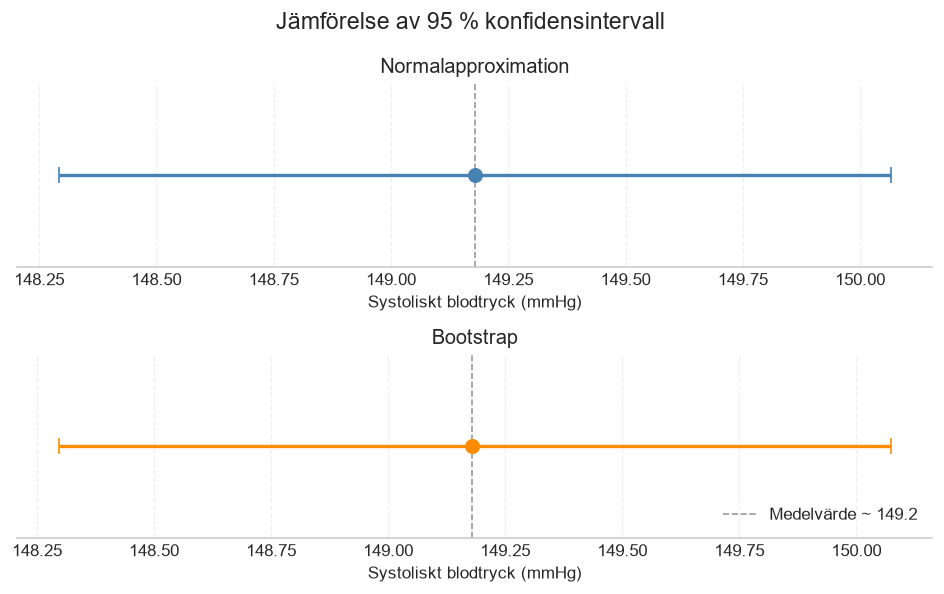

In [56]:
fig, ax = plt.subplots(2, 1, sharex=False)

# Normalapproximation
ax[0].errorbar(
    mean_bp,
    0,
    xerr=[[mean_bp - lower_normal], [upper_normal - mean_bp]],
    fmt="o",
    color="steelblue",
    markersize=8,
    capsize=5,
    elinewidth=2
)

ax[0].set_title("Normalapproximation")
ax[0].axvline(mean_bp, linestyle="--", color="0.6", linewidth=1, label=f"Medelvärde ~ {mean_bp:.1f}")   # vi får en grå linje
ax[0].set_yticks([])
ax[0].grid(axis="x", linestyle="--", alpha=0.3)
ax[0].set_xlabel("Systoliskt blodtryck (mmHg)")

# Bootstrap
ax[1].errorbar(
    mean_bp,
    0,
    xerr=[[mean_bp - lower_boot], [upper_boot - mean_bp]],
    fmt="o",
    color="darkorange",
    markersize=8,
    capsize=5,
    elinewidth=2

)
ax[1].axvline(mean_bp, linestyle="--", color="0.6", linewidth=1, label=f"Medelvärde ~ {mean_bp:.1f}")   # vi får en grå linje
ax[1].set_title("Bootstrap")
ax[1].set_yticks([])
ax[1].grid(axis="x", linestyle="--", alpha=0.3)
ax[1].set_xlabel("Systoliskt blodtryck (mmHg)")

fig.suptitle("Jämförelse av 95 % konfidensintervall", fontsize=14)

# Tar bort onödiga ramar
for a in ax:
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)
    a.spines["left"].set_visible(False)

ax[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [57]:
compare = {
    "n": n,
    "mean_bp": mean_bp,
    "std_bp": std_bp,
    "standard_error": standard_error,
    "lower_normal": lower_normal,
    "upper_normal": upper_normal,
    "lower_boot": lower_boot,
    "upper_boot": upper_boot
}
print("---------- Medelvärde systoliskt blodtryck ----------")
print(f"n = {compare['n']}")
print(f"Medelvärde:         {compare['mean_bp']:.2f} mmHg")
print(f"SD:                 {compare['std_bp']:.2f}")
print(f"SE:                 {compare['standard_error']:.2f}")
print(f"95% CI (normal):    {compare['lower_normal']:.2f} – {compare['upper_normal']:.2f}")
print(f"95% CI (bootstrap): {compare['lower_boot']:.2f} – {compare['upper_boot']:.2f}")


---------- Medelvärde systoliskt blodtryck ----------
n = 800
Medelvärde:         149.18 mmHg
SD:                 12.79
SE:                 0.45
95% CI (normal):    148.29 – 150.07
95% CI (bootstrap): 148.30 – 150.07


**Jämförelse av de två 95-procentiga konfidensintervallen för systoliskt blodtryck**

- Normalapproximations-metoden använder medelvärdet och standardfelet för att uppskatta ett intervall där populationens sanna medelvärde förväntas ligga. Metoden bygger på att stickprovsmedelvärdet är ungefär normalfördelat, det är ofta rimligt vid tillräckligt stora stickprov.

- Bootstrap: Metoden skapar 10 000 nya stickprov genom slumpmässig dragning med återläggning från originaldatan. Medelvärdet beräknas för varje stickprov och de 2,5 och 97,5 percentilerna används som konfidensintervallets gränser.

- De två intervallens nedre och övre gränser är väldigt lika och tyder det på att metoderna ger ungefär samma uppskattning av osäkerheten. Intervallet är ganska smalt och det kan tyda på att skattningen är nära populationens medelvärde. Eftersom bägge ger ett liknande resultat så kan det bero på att datasetet är tillräckligt stort och observationerna är oberoende. Om resultatet hade varit olika hade det kunnat bero på fördelningen eller stickprovets egenskaper.

## Hypotesprövning ”Rökare har högre medel-blodtryck än icke-rökare”

Ett Welch's t-test används. Det jämför medelvärdet mellan två oberoende grupper och fungerar också när grupperna har olika variation och antal. Här jämförs 213 rökare med 587 icke-rökare. Testet är ensidigt eftersom vi vill undersöka om rökare har ett **högre** genomsnittligt blodtryck än icke-rökare. Signifikansnivån sätts till 5% (α = 0,05).

Testet utgår från hypoteserna:
- Nollhypotes (H₀): Rökare har inte ett högre medel-blodtryck än icke-rökare.
- Alternativhypotes (H₁): Rökare har ett högre medel-blodtryck än icke-rökare.
    - H₀: μR ≤ μI 
    - H₁: μR > μI  


In [58]:
# Welchs t-test 
smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"].values
non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"].values

n_smokers = len(smokers)
n_non_smokers = len(non_smokers)

mean_smokers = smokers.mean()
mean_non_smokers = non_smokers.mean()
diff = mean_smokers - mean_non_smokers


# Ensidigt t-test och variansen antas inte behöva vara lika
t_stat, p_value = stats.ttest_ind(
    smokers,
    non_smokers,
    equal_var=False,
    alternative="greater"
)

print(f"""
----------- Welch's t-test -----------
Antal rökare:             {n_smokers}
Antal icke-rökare:        {n_non_smokers}
Medelvärde rökare:        {mean_smokers:.3f}
Medelvärde icke-rökare:   {mean_non_smokers:.3f}
Skillnad i medelvärde:    {diff:.3f}
t-statistika:             {t_stat:.3f}
p-värde:                  {p_value:.3f}
""")

if p_value < 0.05:
    print("Resultat: Vi förkastar nollhypotesen.")
    print("Det finns statistiskt stöd för att rökare har högre systoliskt blodtryck än icke-rökare")
else:
    print("Resultat: Vi kan inte förkasta nollhypotesen.")
    print("Det finns inte tillräckligt statistiskt stöd för att rökare har högre systoliskt blodtryck än icke-rökare")


----------- Welch's t-test -----------
Antal rökare:             213
Antal icke-rökare:        587
Medelvärde rökare:        149.525
Medelvärde icke-rökare:   149.053
Skillnad i medelvärde:    0.472
t-statistika:             0.450
p-värde:                  0.326

Resultat: Vi kan inte förkasta nollhypotesen.
Det finns inte tillräckligt statistiskt stöd för att rökare har högre systoliskt blodtryck än icke-rökare


**Tolkning:** Welch's t-testet (ensidigt) ger en t-statistik på 0,450 och ett p-värde på 0,326. Eftersom p-värdet är större än signifikansnivån 0,05 kan vi inte förkasta nollhypotesen. Resultatet ger inte statistiskt signifikant stöd för att rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare. Att resultat inte är statistiskt signifikant innebär inte att det saknas en skillnad, utan att det inte finns tillräckligt statistiskt stöd för att dra den slutsatsen. Det genomsnittliga systoliska blodtrycket var 149,52 mmHg hos rökare och 149,05 mmHg hos icke-rökare. Skillnaden mellan gruppernas medelvärden är ca 0,47mmHg. Även om rökarnas medelvärde är något högre än icke-rökarnas är skillnaden liten och kan bero på slumpmässig variation.

Begränsningar
- Welch t-test bygger på att grupperna ska vara oberoende av varandra och observationerna inom varje grupp ska vara oberoende. 
Blodtrycket antas vara ungefärligt normalfördelat inom grupperna, särskilt vid mindre urval. Antalet i urvalet som gjort här gör testet ganska robust.
- Testet undersöker skillnaden i medelvärden och tar inte hänsyn till andra faktorer som kan påverka blodtrycket, exempelvis ålder och livsstil.

## Gör en simulering för att undersöka hur säkert ditt hypotes­test är
Simuleringarna används för att undersöka hur möjligheten att upptäcka en skillnad förändras beroende på hur stor skillnaden mellan grupperna är. Här genomförs 2 000 simuleringar för varje effektstorlek. Power visar hur stor sannoliketen är att testet upptäcker en skillnad i blodtryck mellan rökare och icke-rökare när den finns. En vanlig riktlinje är att power bör vara minst 80 %.

Jag har valt att testa skillnader på 0,47, 1, 2, 3 och 5 mmHg. Den första är 0,47 mmHg eftersom skillnaden i datasetet var cirka 0,47 mmHg. Sedan ökas skillnaden på för att undersöka hur det påverkar testets förmåga att upptäcka dessa. Eftersom det är två oberoende grupper som jämförs används Welchs t-test även i simuleringen. I varje simulering skapas två grupper med lika många personer och ungefär samma spridning i blodtrycket som i originaldata. Därefter testas om rökarnas blodtryck är högre än icke-rökarnas, med en signifikansnivå på 0,05. Power beräknas genom att undersöka hur stor andel av simuleringarna som ger ett statistiskt signifikant resultat, p < 0,05.

In [59]:
np.random.seed(42)

n_simulations = 2000
alpha = 0.05


# Ursprungliga värden
mean_non = non_smokers.mean()
std_smokers = smokers.std(ddof=1)
std_non = non_smokers.std(ddof=1)

# Vad händer med power när skillnaden mellan grupperna ökar?
# Hur svårt är det att upptäcka skillnaderna mellan rökare och icke-rökare
effect_sizes = [0.47, 1, 2, 3, 5]

# Simulera experiment
power_results = []

# Upprepas för varje effekstorlek
for effect in effect_sizes:

    significant = 0
    # Upprepas 2000 ggr
    for i in range(n_simulations):
        # Simulerad grupp med rökare
        simulated_smokers = np.random.normal(
            # Rökarnas medelvärde utgår från icke-rökarnas medelvärde och lägger till effekten
            mean_non + effect,
            std_smokers,
            n_smokers
        )
        # Simulerad grupp med icke-rökare
        simulated_non = np.random.normal(
            mean_non,
            std_non,
            n_non_smokers
        )

# Welchs t-test - kräver inte att grupperna har samma varians. 
# Det är lämpligt när grupperna har olika storlek och variansen inte nödvändigtvis är lika
# ett ensidigt test används
        _, p = stats.ttest_ind(
            simulated_smokers,
            simulated_non,
            equal_var=False,
            alternative="greater"
        )

        if p < alpha:
            significant += 1

    simulated_power = significant / n_simulations

    power_results.append({
        "effekt": effect,
        "antal_signifikanta": significant,
        "power": simulated_power
    })


simulated_power = pd.DataFrame(power_results)

# Cohens d - standardiserar skillnaden i medel med den typiska spridningen
pooled_std = np.sqrt(
    ((n_smokers - 1) * std_smokers**2 +
     (n_non_smokers - 1) * std_non**2) /
    (n_smokers + n_non_smokers - 2)
)
cohens_d = diff / pooled_std


display_summary = simulated_power.copy()
display_summary = display_summary.rename(
    columns={"power": "power (%)"}
)
display_summary["power (%)"] = round(display_summary["power (%)"] * 100, 2)

print(f"Standardavvikelse rökare: {std_smokers:.2f}")
print(f"Standardavvikelse icke-rökare: {std_non:.2f}")
print(f"Cohens d: {cohens_d:.2f}")
display(display_summary)

Standardavvikelse rökare: 13.27
Standardavvikelse icke-rökare: 12.63
Cohens d: 0.04


,effekt,antal_signifikanta,power (%)
0,0.47,217,10.85
1,1.00,470,23.50
2,2.00,1180,59.00
3,3.00,1766,88.30
4,5.00,2000,100.00


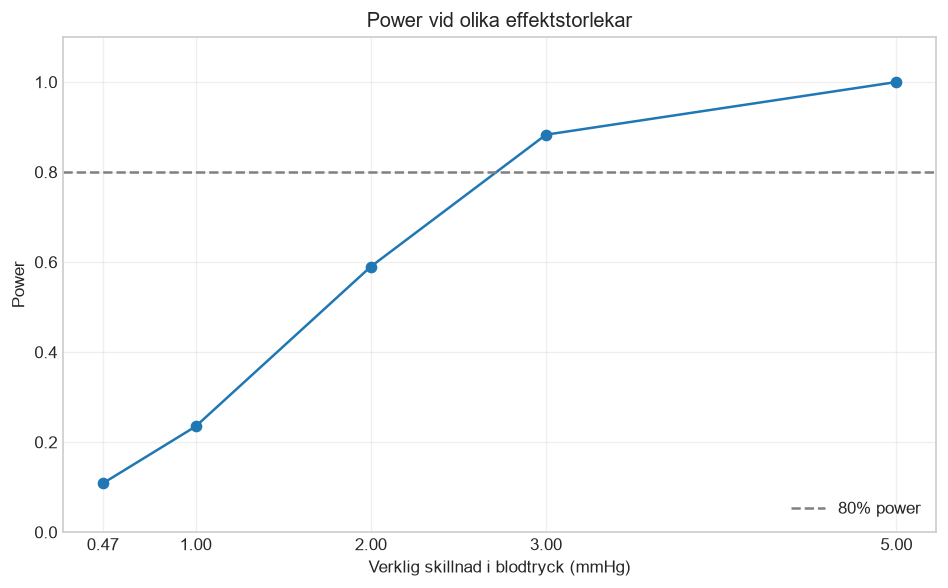

In [61]:
plt.plot(
    effect_sizes,
    simulated_power["power"].values,
    marker="o"
)

plt.axhline(
    y=0.80,
    color="grey",
    linestyle="--",
    label="80% power"
)

plt.title("Power vid olika effektstorlekar")
plt.xlabel("Verklig skillnad i blodtryck (mmHg)")
plt.ylabel("Power")
plt.ylim(0, max(simulated_power["power"].values) + 0.1)
plt.xticks(effect_sizes)
plt.legend(loc="lower right")
plt.tight_layout()
plt.grid(alpha=0.3)
plt.show()

**Tolkning:** Diagrammet visar att power ökar med effektstorlek. Vid små skillnader på 0,47 och 1 mmHg är sannolikheten att upptäcka en signifikant skillnad låg. Vid 2 mmHg ökar power till 59%, vid 3 mmHg är den 88,3 %, medan en stor skillnad på 5 mmHg nästan alltid hittas. Det kan betyda att testet lättare upptäckar stora skillnader, men är sämre på att hitta små skillnader i blodtryck. Vid den minsta simulerade effektstorleken 0,47 mmHg är power 10,85%. Det kan vara en förklaring till att den ursprungliga hypotesprövningen inte blev statistiskt signifikant (p=0,326). Skillnaden mellan grupperna är 0,47 mmHg. Det kan innebära att skillnaden är svår att upptäcka om variansen är relativt hög. Standardavvikelsen är 13,27 för rökare och 12,63 för icke-rökare. Värdena varierar alltså ungefär lika mycket i båda grupperna. Enligt Cohens d motsvarar skillnaden mellan rökare och icke-rökare bara 0,04 standardavvikelser.

Begränsningar
- Power påverkas bland annat av effektstorlek, stickprovsstorlek, variation i data och signifikansnivå. 
- Små skillnader kräver ofta fler deltagare för att få tillräckligt hög power
- En hög power innebär mindre risk för typ II-fel, det vill säga att missa en verklig skillnad. 
- Effekstorlekarna som valts kanske inte motsvarar de skillnader som finns i populationen.